# Cavity circuit test: first-iteration MATLAB checkpoint

Follow the same workflow as **translation_checkpoint_167**: prepare inputs in Python, run the original MATLAB solver manually to a breakpoint, save its workspace variables, and compare them here.

No MATLAB Engine, automatic MATLAB launch, or separate reimplementation of the MATLAB circuit is used.

1. Choose a test case and run the Python cells.
2. Export the inputs, local field-map text files, and Python checkpoint.
3. Follow the printed MATLAB commands and stop just after `Vnc` and `Vnp` are assigned for `nn = 1`.
4. Save the MATLAB checkpoint, stop the debugger, and rerun the comparison cells.

**Compared:** references, grids, normalized mode profiles `ez`, `C3`, initial current harmonics, `Vin`, beam excitation, `Mc`, `B`, `Vnc`, and `Vnp`. We also calculate `Vng` using the gap-voltage expression found later in the original solver.

**Not yet compared:** the operating field `Emz`. Its voltage-to-field assembly remains unresolved in the current MATLAB source. Agreement of normalized profiles or circuit voltages does not, by itself, validate that assembly.

In [1]:
from pathlib import Path
from dataclasses import replace
import sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from IPython.display import Markdown, display

current_directory = Path.cwd().resolve()
project_directory = next(
    path for path in (
        current_directory,
        current_directory / "pyKlyC",
        current_directory.parent,
    )
    if (path / "src" / "solver" / "cavity_state.py").exists()
)
notebook_directory = project_directory / "Notebooks"
matlab_directory = project_directory.parent / "KlyC"
matlab_source = matlab_directory / "KLJCmainsv22.m"
sys.path.insert(0, str(project_directory / "src"))

from constants import esign, eta0
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.cavity_field_map import CavityFieldMap
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters
from solver.cavity_fields import CavityFields
from solver.beam_state import BeamState
from solver.cavity_state import CavityState

np.set_printoptions(precision=12, linewidth=160)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def show_table(headers, rows):
    text = "| " + " | ".join(headers) + " |\n"
    text += "| " + " | ".join("---" for _ in headers) + " |\n"
    for row in rows:
        text += "| " + " | ".join(str(value) for value in row) + " |\n"
    display(Markdown(text))

## 1. Choose the excitation and cavities

| test_case | Input-cavity power | Entrance current |
|---|---|---|
| `drive_only` | 60 W | Unmodulated: RF harmonics are zero up to roundoff |
| `beam_only` | 0 W | Prescribed 5% first-harmonic modulation |
| `combined` | 60 W | Same prescribed modulation |

The DC current stays nonzero in all cases because it defines the normalization. The modulated current is \(-16[1+a\cos(t_0+\phi)]\) A. With the code's harmonic convention, its initial first harmonic is \(I_{z,1}=i\,a\,e^{i\phi}\).

The default selects all five cavities from the preceding notebooks, testing input, bunching, and output branches in one solve. Set `cavity_indices = np.array([0])` to isolate the input cavity. These are zero-based indices into the parameter arrays.

This is an **initialization snapshot**, not a self-consistent bunched beam. No beam tracking is performed. Use normal klystron mode (`mono = 1`), no power ramp, and `Lsb = pi`, which the original MATLAB solver hardcodes.

In [2]:
test_case = "combined"  # "drive_only", "beam_only", or "combined"
cavity_indices = np.arange(5)  # np.array([0]) for just the input cavity

Nt = 128
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
tn1 = t0.copy()
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)
modulation = 0.05 if test_case != "drive_only" else 0.0
phase = np.pi / 4.0
Izt = -16.0 * (1.0 + modulation * np.cos(t0 + phase))

Nbeam = 1
rm1, rm2, rc = 0.0, 6.0, 10.0
xb = yb = xd = yd = 0.0
f = 1.0
Ns = 8
Nz = 256
N = 200

type = np.array([0, 1, 1, 1, -1])[cavity_indices]
nh = np.ones(len(cavity_indices), dtype=int)
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])[cavity_indices]
RtoQ = np.array([182.8959, 116.9999, 102.0570, 123.6318, 180.3864])[cavity_indices]
M = np.array([0.9225, 0.8930, 0.8192, 0.9518, 0.9325])[cavity_indices]
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])[cavity_indices]
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])[cavity_indices]
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])[cavity_indices]
Pin = np.array([60.0, 0.0, 0.0, 0.0, 0.0])[cavity_indices]
if test_case == "beam_only":
    Pin = np.zeros_like(Pin)
Nc = len(cavity_indices)
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)
kai = np.zeros((Nc, Nc), dtype=complex)
cavityname = " ".join(f"guide_cavity_{kk + 1}" for kk in cavity_indices)

z0 = -100.0
L = 3000.0
rcv = np.array([[z0, z0 + L], [1.0, 1.0]])

# Full original function interface; stop before dynamics.
Nlimit = 100
Ntimes = 10
Rlimit = 1.0e-4
iterfactor = 0.5
factor = 0.0             # Disable space charge for this circuit-only test.
factorregion = 10.0
fillfactor = 1.0
DCSPfactor = 1.0
evolutionmethod = np.array([0.005, 2.0])
figuredisp = "off"
moviedisp = np.array([0, 0, 0, 0, 1])  # No ramp and no convergence window.
GIFpara = np.array([64.0, -0.2, 1.0, 0.0, 3.0 * rc, 0.0])
Npin = 10
mono = 1

assert test_case in ("drive_only", "beam_only", "combined")
assert np.all((nh >= 1) & (nh <= Ns))
assert np.all(np.isin(type, [-1, 0, 1]))

numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=Nlimit, Ntimes=Ntimes,
    Rlimit=Rlimit, iterfactor=iterfactor,
    evolutionmethod=evolutionmethod,
)
beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc,
    xb=xb, yb=yb, xd=xd, yd=yd,
    Nt=Nt, t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(numerical, cavities, tube, beam, reference, factorregion)
field_maps = CavityFieldMap.from_circuit_parameters(
    cavityname=cavities.names, f0=f0, RtoQ=RtoQ, M=M, s=reference.s, N=N,
)
cavity_fields = CavityFields.calculate(numerical, cavities, grid, reference, field_maps)
state = BeamState.initialize(numerical, beam, grid, reference)

np.testing.assert_allclose(state.Iz[0, 0], 1j * modulation * np.exp(1j * phase),
                           rtol=1e-12, atol=1e-14)
print("Test case:", test_case)
print("Cavities:", cavities.names)
print("Initial Iz[0, 0]:", state.Iz[0, 0])
print(f"Reference: I0={reference.I0:g} A, U0={reference.U0:g} kV")

Test case: combined
Cavities: ('guide_cavity_1', 'guide_cavity_2', 'guide_cavity_3', 'guide_cavity_4', 'guide_cavity_5')
Initial Iz[0, 0]: (-0.035355339059327306+0.03535533905932735j)
Reference: I0=16 A, U0=180 kV


## 2. One Python circuit solve

The beam excitation at each cavity's harmonic is

\[
I_{\mathrm{beam},k}
=-e_{\mathrm{sign}}N_{\mathrm{beam}}
\int C_3(z,k)\,I_z(z,n_{h,k})\,dz.
\]

The integration coordinate is normalized `grid.z`, **not** `grid.zi` in mm.

\[
M_c
\begin{bmatrix}V_{np,1}&V_{nc,1}&\cdots&V_{np,N_c}&V_{nc,N_c}\end{bmatrix}^{T}
=B.
\]

`Ibeam` below is an inspection variable for the expression inside the MATLAB right-hand side, not an additional excitation.

We also evaluate the original code's RF gap-voltage expression,
\(V_{ng,k}=U_0V_{nc,k}k_{0,k}^{-1/2}\int e_z(z_i,k)\,dz_i\), in kV. MATLAB normally calculates this after the iteration loop; the debugger instructions calculate it at this checkpoint solely for comparison.

Mc =
 [[-1.827566688250e+01-2.238123694993e-15j -1.000000000000e+00+0.000000000000e+00j  0.000000000000e+00+0.000000000000e+00j
   0.000000000000e+00+0.000000000000e+00j  0.000000000000e+00+0.000000000000e+00j  0.000000000000e+00+0.000000000000e+00j
   0.000000000000e+00+0.000000000000e+00j  0.000000000000e+00+0.000000000000e+00j  0.000000000000e+00+0.000000000000e+00j
   0.000000000000e+00+0.000000000000e+00j]
 [ 5.471756551646e-02+6.700969146687e-18j -6.087168249330e-05-0.000000000000e+00j  0.000000000000e+00+0.000000000000e+00j
   0.000000000000e+00-0.000000000000e+00j  0.000000000000e+00+0.000000000000e+00j  0.000000000000e+00-0.000000000000e+00j
   0.000000000000e+00+0.000000000000e+00j  0.000000000000e+00-0.000000000000e+00j  0.000000000000e+00+0.000000000000e+00j
   0.000000000000e+00-0.000000000000e+00j]
 [ 0.000000000000e+00+0.000000000000e+00j  0.000000000000e+00+0.000000000000e+00j  1.000000000000e+00+0.000000000000e+00j
   0.000000000000e+00+0.000000000000e+00j  0.000000000

| Cavity | Vin | Ibeam | Vnp | Vnc | Vng [kV] |
| --- | --- | --- | --- | --- | --- |
| guide_cavity_1 | 0.00118123 | 0.000824917-0.000824917j | 0.0159097-0.0147755j | -0.312347+0.270032j | -39.1731+33.8661j |
| guide_cavity_2 | 0 | 0.000659784-0.000659784j | 0+0j | -0.0555455-0.0550763j | -5.57173-5.52467j |
| guide_cavity_3 | 0 | 0.000616211-0.000616211j | 0+0j | -0.019596-0.0195333j | -1.83585-1.82997j |
| guide_cavity_4 | 0 | 0.000678223-0.000678223j | 0+0j | -0.0116546-0.011631j | -1.20174-1.19931j |
| guide_cavity_5 | 0 | 0.00081924-0.00081924j | 0.00577338-0.00577338j | -0.0408239+0.0408239j | -5.0847+5.0847j |


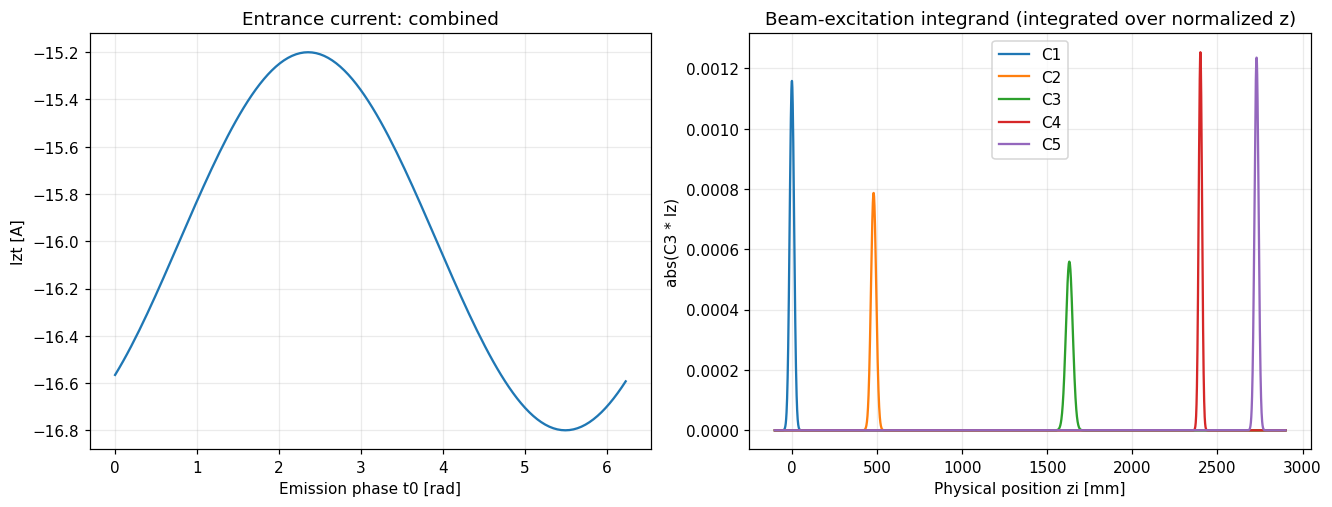

In [3]:
cavity_state = CavityState.initialize(numerical, cavities, beam, reference)
cavity_state.solve(numerical, cavities, cavity_fields, beam, state, grid)

Ibeam = np.zeros(Nc, dtype=complex)
Vng = np.zeros(Nc, dtype=complex)
for kk in range(Nc):
    Ibeam[kk] = -esign * Nbeam * np.trapezoid(
        cavity_fields.C3[:, kk] * state.Iz[:, nh[kk] - 1], x=grid.z
    )
    Vng[kk] = reference.U0 * cavity_state.Vnc[kk] / np.sqrt(grid.k0[kk]) * np.trapezoid(
        cavity_fields.ez[:, kk], x=grid.zi
    )

print("Mc =\n", cavity_state.Mc)
print("B =\n", cavity_state.B)
show_table(
    ["Cavity", "Vin", "Ibeam", "Vnp", "Vnc", "Vng [kV]"],
    [
        [name, f"{cavity_state.Vin[kk]:.6g}", f"{Ibeam[kk]:.6g}",
         f"{cavity_state.Vnp[kk]:.6g}", f"{cavity_state.Vnc[kk]:.6g}", f"{Vng[kk]:.6g}"]
        for kk, name in enumerate(cavities.names)
    ],
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].plot(t0, Izt)
axes[0].set(xlabel="Emission phase t0 [rad]", ylabel="Izt [A]",
            title=f"Entrance current: {test_case}")
for kk in range(Nc):
    axes[1].plot(grid.zi, np.abs(cavity_fields.C3[:, kk] * state.Iz[:, nh[kk] - 1]),
                 label=f"C{kk + 1}")
axes[1].set(xlabel="Physical position zi [mm]", ylabel="abs(C3 * Iz)",
            title="Beam-excitation integrand (integrated over normalized z)")
for ax in axes:
    ax.grid(alpha=0.25)
axes[1].legend()
plt.show()

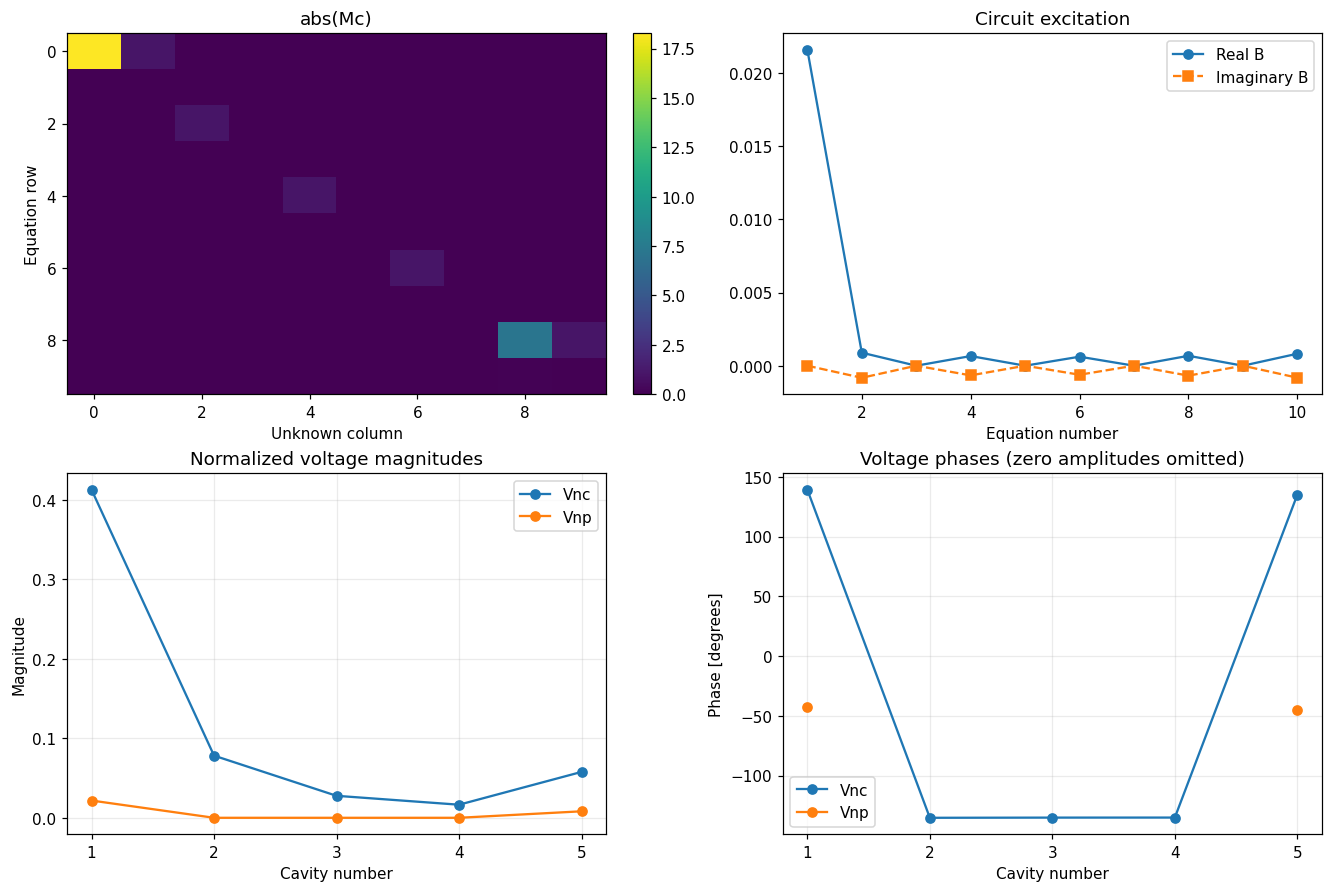

In [4]:
cavity_numbers = np.arange(1, Nc + 1)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")

plot = axes[0, 0].imshow(np.abs(cavity_state.Mc), aspect="auto")
axes[0, 0].set(title="abs(Mc)", xlabel="Unknown column", ylabel="Equation row")
fig.colorbar(plot, ax=axes[0, 0])
axes[0, 1].plot(np.arange(1, 2 * Nc + 1), cavity_state.B.real, "o-", label="Real B")
axes[0, 1].plot(np.arange(1, 2 * Nc + 1), cavity_state.B.imag, "s--", label="Imaginary B")
axes[0, 1].set(title="Circuit excitation", xlabel="Equation number")
axes[0, 1].legend()

for value, label in [(cavity_state.Vnc, "Vnc"), (cavity_state.Vnp, "Vnp")]:
    axes[1, 0].plot(cavity_numbers, abs(value), "o-", label=label)
    phase_plot = np.where(abs(value) > 1e-12, np.angle(value, deg=True), np.nan)
    axes[1, 1].plot(cavity_numbers, phase_plot, "o-", label=label)
axes[1, 0].set(title="Normalized voltage magnitudes", ylabel="Magnitude")
axes[1, 1].set(title="Voltage phases (zero amplitudes omitted)", ylabel="Phase [degrees]")
for ax in axes[1]:
    ax.set(xlabel="Cavity number", xticks=cavity_numbers)
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## 3. Python consistency checks

These checks are independent of the MATLAB comparison. They verify the linear-system residual, superposition of external and beam excitation, and voltage scaling with the square root of input power.

The reference beam and `C3` are held fixed while testing source scaling. Each diagnostic uses a fresh `CavityState`; the baseline solution is not modified.

In [5]:
solution = np.empty(2 * Nc, dtype=complex)
solution[0::2] = cavity_state.Vnp
solution[1::2] = cavity_state.Vnc
np.testing.assert_allclose(cavity_state.Mc @ solution, cavity_state.B, rtol=1e-10, atol=1e-12)
residual = np.linalg.norm(cavity_state.Mc @ solution - cavity_state.B)
print(f"Linear-system residual norm: {residual:.3e}")

solutions = {}
for label, power_scale, current_scale in [
    ("external", 1.0, 0.0),
    ("beam", 0.0, 1.0),
    ("four_power", 4.0, 0.0),
]:
    cavities_test = replace(cavities, Pin=power_scale * cavities.Pin)
    state_test = replace(state, Iz=current_scale * state.Iz)
    circuit_test = CavityState.initialize(numerical, cavities_test, beam, reference)
    circuit_test.solve(numerical, cavities_test, cavity_fields, beam, state_test, grid)
    solutions[label] = circuit_test

for name in ("Vnc", "Vnp"):
    np.testing.assert_allclose(
        getattr(cavity_state, name),
        getattr(solutions["external"], name) + getattr(solutions["beam"], name),
        rtol=1e-10, atol=1e-12,
    )
    np.testing.assert_allclose(
        getattr(solutions["four_power"], name), 2.0 * getattr(solutions["external"], name),
        rtol=1e-10, atol=1e-12,
    )

print("PASS: linear solve and external/beam superposition.")
print("PASS: four times the incident power gives twice the externally driven voltage.")
if not np.any(Pin[type == 0]):
    print("Note: power scaling is a zero-drive check here; use combined or drive_only for a nonzero test.")

Linear-system residual norm: 2.661e-18
PASS: linear solve and external/beam superposition.
PASS: four times the incident power gives twice the externally driven voltage.


## 4. Export the inputs and Python checkpoint

Files go into `Notebooks/circuit_checkpoint/<test_case>/`, separate from the older translation checkpoint. Rerunning this cell updates only this test's generated inputs and Python checkpoint; it does not replace an existing MATLAB result.

The export includes:

- All 45 arguments of the original MATLAB function. Numeric integer inputs are written as MATLAB doubles to avoid unintended integer arithmetic; `Y0` is converted to one-based indexing.
- One local two-column text file per cavity, using the **same samples** as Python. MATLAB loads them by `cavityname`.
- The Python variables to compare.

The comparison checks the input values, profiles, and grid too, so a checkpoint from different parameters is not silently accepted. After changing inputs, rerun MATLAB and save its checkpoint again.

In [ ]:
checkpoint_directory = notebook_directory / "circuit_checkpoint" / test_case
checkpoint_directory.mkdir(parents=True, exist_ok=True)
matlab_input_file = checkpoint_directory / "matlab_test_inputs.mat"
python_file = checkpoint_directory / "python_checkpoint_circuit.mat"
matlab_file = checkpoint_directory / "matlab_checkpoint_circuit.mat"

matlab_inputs = {
    "Nc": Nc, "Ns": Ns, "Nz": Nz, "Nlimit": Nlimit, "Ntimes": Ntimes,
    "Rlimit": Rlimit, "factor": factor, "factorregion": factorregion,
    "fillfactor": fillfactor, "DCSPfactor": DCSPfactor, "iterfactor": iterfactor,
    "z0": z0, "L": L, "Nbeam": Nbeam, "rm2": rm2, "rm1": rm1, "rc": rc,
    "xb": xb, "yb": yb, "xd": xd, "yd": yd, "Nt": Nt, "t0": t0, "f": f,
    "Ut": Ut, "Izt": Izt, "type": type, "nh": nh, "f0": f0,
    "Qext": Qext, "Qin": Qin, "zshift": zshift, "Pin": Pin,
    "gaman": gaman, "cavityname": cavityname, "tn1": tn1, "Y0": Y0 + 1,
    "evolutionmethod": evolutionmethod, "figuredisp": figuredisp,
    "moviedisp": moviedisp, "GIFpara": GIFpara, "Npin": Npin,
    "kai": kai, "rcv": rcv, "mono": mono,
}
for name, value in matlab_inputs.items():
    if np.asarray(value).dtype.kind in "iub":
        matlab_inputs[name] = np.asarray(value, dtype=float)

savemat(matlab_input_file, matlab_inputs, oned_as="row")
for name, field_map in field_maps.items():
    np.savetxt(
        checkpoint_directory / f"{name}.txt",
        np.column_stack((field_map.z_mm, field_map.e_z)),
        fmt="%.17e",
    )

python_variables = {
    name: value for name, value in matlab_inputs.items()
    if np.asarray(value).dtype.kind not in "US"
}
python_variables.update({
    "nn": 1, "Iz0": reference.Iz0, "I0": reference.I0, "U0": reference.U0,
    "s": reference.s, "gama": reference.gama, "vn1": reference.vn1,
    "w": grid.w, "w0": grid.w0, "k0": grid.k0, "Lsb": cavities.Lsb,
    "betae": grid.betae, "dz": grid.dz, "zi": grid.zi, "z": grid.z, "dt": grid.dt,
    "ez": cavity_fields.ez, "C3": cavity_fields.C3,
    "Iz": state.Iz, "IzDC": state.IzDC, "QQ": state.QQ, "QQDC": state.QQDC,
    "Vin": cavity_state.Vin, "Ibeam": Ibeam, "Mc": cavity_state.Mc,
    "B": cavity_state.B, "Vnc": cavity_state.Vnc, "Vnp": cavity_state.Vnp, "Vng": Vng,
})
savemat(python_file, python_variables, oned_as="column")
print(f"Saved {matlab_input_file}")
print(f"Saved {Nc} local field-map text files in {checkpoint_directory}")
print(f"Saved {python_file}")
print(f"Expected MATLAB result: {matlab_file}")

## 5. Run the original MATLAB solver to the breakpoint

The next cell **prints commands**; it does not launch MATLAB or edit the source.

The breakpoint is located from the first `if mono==0 && nn==1` after the assignments to `Vnp` and `Vnc` (line 293 in the current file). MATLAB stops **before** executing the selected line, so both voltage vectors are already available.

A known issue in the local source is a stray `N` in `Nesz=zeros(length(zi),2)N;`. If the warning below appears, that syntax typo must be corrected to `Nesz=zeros(length(zi),2);` before MATLAB can parse/run the function. This notebook does not make that edit.

In MATLAB:

1. Run the first printed block: select the export folder, add the source folder, and install the breakpoint.
2. Confirm that `which KLJCmainsv22` points to the intended file.
3. When MATLAB is paused, run the second block. It computes inspection variables and saves the checkpoint in the current test folder.
4. Use `dbquit`, **not** `dbcont`: this test stops before beam dynamics.

The 13 function outputs are not expected to be assigned in the base workspace: the function is stopped early. The saved checkpoint is the result of this test.

In [ ]:
matlab_lines = matlab_source.read_text(encoding="utf-8-sig").splitlines()
breakpoint_line = next(
    number for number, line in enumerate(matlab_lines, start=1)
    if line.strip().startswith("if mono==0 && nn==1")
)

for number, line in enumerate(matlab_lines, start=1):
    if "Nesz=zeros(length(zi),2)N;" in line:
        print(f"MATLAB RUN BLOCKER at line {number}: {line.strip()}")
        print("Correct the stray N before running MATLAB. Source left unchanged.\n")

matlab_folder = matlab_directory.as_posix().replace("'", "''")
export_folder = checkpoint_directory.as_posix().replace("'", "''")
run_commands = f"""% Run in the MATLAB Command Window.
cd('{export_folder}')
addpath('{matlab_folder}')
which KLJCmainsv22
load('matlab_test_inputs.mat')
dbstop in KLJCmainsv22 at {breakpoint_line} if nn==1

[output1,output2,output3,output4,output5,output6,output7, ...
 output8,output9,output10,output11,output12,output13] = ...
KLJCmainsv22(Nc,Ns,Nz,Nlimit,Ntimes,Rlimit,factor,factorregion, ...
    fillfactor,DCSPfactor,iterfactor,z0,L,Nbeam,rm2,rm1,rc,xb,yb, ...
    xd,yd,Nt,t0,f,Ut,Izt,type,nh,f0,Qext,Qin,zshift,Pin,gaman, ...
    cavityname,tn1,Y0,evolutionmethod,figuredisp,moviedisp,GIFpara, ...
    Npin,kai,rcv,mono);"""

save_commands = """% Run only when stopped inside KLJCmainsv22 at the checkpoint.
assert(nn == 1)
Ibeam = zeros(1,Nc);
Vng = zeros(1,Nc);
for k = 1:Nc
    Ibeam(k) = -esign*Nbeam*trapz(z,C3(:,k).*Iz(:,nh(k)));
    Vng(k) = U0*Vnc(k)*k0(k)^(-1/2)*trapz(zi,ez(:,k));
end
save('matlab_checkpoint_circuit.mat', ...
"""
names = list(python_variables)
for start in range(0, len(names), 7):
    save_commands += "    " + ",".join(f"'{name}'" for name in names[start:start + 7]) + ", ...\n"
save_commands += "    '-v7');\ndbquit\n"
save_commands += f"dbclear in KLJCmainsv22 at {breakpoint_line}"

fence = chr(96) * 3
display(Markdown("### Run the solver\n\n" + fence + "matlab\n" + run_commands + "\n" + fence))
display(Markdown("### Save at the breakpoint, then stop\n\n" + fence + "matlab\n" + save_commands + "\n" + fence))

## 6. Load and compare the MATLAB checkpoint

Run this cell after saving the MATLAB file. A missing file means **not yet compared**, not a passed test.

Comparison is on the complex values, so both magnitude and phase errors are detected. Row/column layout is ignored only for scalars/vectors; matrices such as `Mc`, `Iz`, and `C3` must have the correct shape. Non-finite values and missing variables fail.

The relative error is \(\max|x_{\mathrm{Python}}-x_{\mathrm{MATLAB}}|/\max(\max|x_{\mathrm{MATLAB}}|,\mathrm{atol})\). Near zero, the absolute error is more useful. The pass criterion uses elementwise `rtol = 1e-10`, `atol = 1e-12`.

Inspect the inputs and upstream quantities first if there is a mismatch, then `Vin`, `Ibeam`, `Mc`, `B`, and finally `Vnc, Vnp, Vng`.

In [ ]:
def compare_checkpoint(python_variables, matlab_variables, rtol=1e-10, atol=1e-12):
    rows = []
    matches = {}
    for name, python_value in python_variables.items():
        if name not in matlab_variables:
            matches[name] = False
            rows.append([name, "MISSING", "-", "-"])
            continue

        python_array = np.asarray(python_value)
        matlab_array = np.asarray(matlab_variables[name])
        if python_array.ndim <= 1:
            python_array = np.squeeze(python_array)
            matlab_array = np.squeeze(matlab_array)

        if python_array.shape != matlab_array.shape:
            matches[name] = False
            rows.append([name, f"SHAPE: {python_array.shape} vs {matlab_array.shape}", "-", "-"])
            continue
        if not np.all(np.isfinite(python_array)) or not np.all(np.isfinite(matlab_array)):
            matches[name] = False
            rows.append([name, "NON-FINITE", "-", "-"])
            continue

        maximum_error = float(np.max(np.abs(python_array - matlab_array)))
        scale = max(float(np.max(np.abs(matlab_array))), atol)
        matches[name] = np.allclose(python_array, matlab_array, rtol=rtol, atol=atol)
        rows.append([name, "PASS" if matches[name] else "FAIL",
                     f"{maximum_error:.3e}", f"{maximum_error / scale:.3e}"])
    return rows, matches


matlab_variables = None
matches = {}
if not matlab_file.exists():
    print("NOT YET COMPARED: MATLAB checkpoint has not been saved.")
    print(f"Expected: {matlab_file}")
    print("Follow section 5, then rerun this cell and the plots below.")
else:
    matlab_variables = loadmat(matlab_file)
    comparison_rows, matches = compare_checkpoint(python_variables, matlab_variables)
    show_table(["Variable", "Result", "Max abs error", "Scaled relative error"], comparison_rows)
    if all(matches.values()):
        print("PASS: all saved quantities agree with this MATLAB checkpoint.")
        print("This validates the checkpoint, not the unresolved Emz assembly or a full nonlinear solve.")
    else:
        print("FAIL: inspect mismatched/missing quantities above; also check for a stale checkpoint.")

## 7. Overlay the complex circuit results

These plots become available after MATLAB results are loaded. Real and imaginary parts avoid misleading phase comparisons near zero amplitude. Matching `Vng` checks the gap-voltage conversion used in MATLAB, not a spatial `Emz` reconstruction.

In [ ]:
plot_names = ("Vnc", "Vnp", "Vng")
can_plot = matlab_variables is not None and all(
    name in matlab_variables and np.asarray(matlab_variables[name]).size == Nc
    for name in plot_names
)
if not can_plot:
    print("Comparison plots await a MATLAB checkpoint with the expected voltage dimensions.")
else:
    fig, axes = plt.subplots(3, 2, figsize=(12, 9), layout="constrained")
    for row, name in enumerate(plot_names):
        python_value = np.asarray(python_variables[name]).reshape(-1)
        matlab_value = np.asarray(matlab_variables[name]).reshape(-1)
        for col, part in enumerate(("real", "imag")):
            ax = axes[row, col]
            ax.plot(cavity_numbers, getattr(python_value, part), "o-", label="Python")
            ax.plot(cavity_numbers, getattr(matlab_value, part), "x--", label="MATLAB")
            ax.set(title=f"{name}: {part}", xlabel="Cavity number", xticks=cavity_numbers,
                   ylabel="kV" if name == "Vng" else "Normalized voltage")
            ax.grid(alpha=0.25)
            ax.legend()
    plt.show()

## Interpretation and next tests

- Run `drive_only`, `beam_only`, and `combined` separately. Each uses its own checkpoint folder.
- Start with `cavity_indices = np.array([0])` for a 2-by-2 system, then use all five cavities.
- To test additional terms, change detuning `f0`, output reflection `gaman`, or inter-cavity coupling `kai`, then regenerate inputs and take a **new** MATLAB checkpoint.
- MATLAB overwrites `Lsb` with pi. Keep that value here unless you deliberately change the MATLAB source too.
- `ez` and `C3` are compared as mode/coupling profiles. `Vnc` and `Vnp` validate the circuit excitation.
- Do not treat a zero-initialized MATLAB `Emz` as a successful operating-field comparison. The voltage-to-field assembly needs to be established separately.

No source files are changed by this notebook, and MATLAB is never launched automatically.